# Real mobile sensor geometry from relative observations

## Problem and evidence
Recover all 1228 planar positions and headings from all 1483 real Intel wheel/laser relative constraints. These are author-distributed **processed real measurements**, not raw scans. The reference is an independently executed original author g2o reconstruction, **not absolute trajectory truth**. Pose zero defines the identity gauge. No original VERTEX estimates are public inputs or used for initialization.

This is geometric sensing: inconsistent local coordinate measurements must form a common spatial trajectory. It is distinct from source localization by acoustic travel time or orthographic shape factorization.

In [1]:
import os,sys,time,json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
T=Path.cwd()
if not (T/'data/raw_data.npz').exists(): T=T.parent
sys.path.insert(0,str(T))
from src.preprocessing import load_data,initialize
from src.physics_model import residual_jacobians,weighted_error,wrap
from src.solvers import reconstruct,normal_equations
from src.visualization import trajectory_figure,residual_figure,convergence_figure,comparison_metrics
data=load_data(T/'data/raw_data.npz')
print({k:(v.shape,str(v.dtype)) for k,v in data.items()})
print('Information eigenvalue range:',np.linalg.eigvalsh(data['information']).min(),np.linalg.eigvalsh(data['information']).max())

{'edge_indices': ((1483, 2), 'int64'), 'relative_poses': ((1483, 3), 'float64'), 'information': ((1483, 3, 3), 'float64')}
Information eigenvalue range: 11.11111033312045 2702706613326.0615


## Physics and acquisition conventions
Let pose i be a position t(i) in metres and rotation R(theta(i)), with counterclockwise theta in radians. The measurement Z(ij) approximates T(i) inverse times T(j), a destination-to-source frame transform. With measured translation z and angle phi, q=R(theta(i)) transpose times (t(j)-t(i)). The canonical error has translation R(phi) transpose times (q-z), and angle wrap(theta(j)-theta(i)-phi). It is the transform's translation/angle **coordinate chart**, not a full SE(2) Lie logarithm. The full information matrix weights these exact coordinates.

The finite connected graph contains 1227 sequential and 256 loop constraints. Information matrices are the distributed nominal weights, with a very large dynamic range; they are not independently validated noise variances. There is no calibrated temporal interval. The global translation/rotation gauge is fixed by pose zero, with no post hoc alignment or arbitrary scale.

## Selected original method and numerical caveat
The original g2o implementation was remotely verified at revision `fd65627348213d56866b24c0b7d054bcf105f0a5`. This is current maintained original-author software, not the paper's 2011 release or exact 2011 experiment. The canonical all-edge objective is half the sum e transpose Omega e. Reports show the full sum. Sequential observed transforms provide the initialization. Analytic world-additive Jacobians build sparse H=J transpose Omega J and g=J transpose Omega e. Fix the anchor, solve H delta=-g, add free-coordinate increments, wrap headings, and perform exactly 20 undamped steps.

Original Eigen uses SimplicialLLT/block AMD; this local implementation uses SciPy SuperLU/COLAMD. Neither changes the equations. The initial anchored H has estimated condition number 7.45e16. An initially frozen first-step coordinate tolerance failed: a same-original-H backend/ordering comparison itself disagreed by up to .00283 in a step coordinate. That failed criterion is retained in provenance and explicitly replaced with original-H/g relative parity and original-system backward-error validation. The final 20-step strict coordinate and heading tolerances remain unchanged. There is no damping or silent information clipping.

In [2]:
start=time.perf_counter()
initial=initialize(data)
fresh,history=reconstruct(data,iterations=20)
elapsed=time.perf_counter()-start
original=np.load(T/'notebooks/reference_outputs/original_method.npz',allow_pickle=False)
ref=original['reconstruction']
(T/'output').mkdir(exist_ok=True)
np.savez_compressed(T/'output/reconstruction.npz',reconstruction=fresh[None])
print('Fresh complete all-edge local reconstruction seconds:',elapsed)
print('Fresh weighted error:',history[0],'->',history[-1])
print('Original independent GN20/50 maximum position difference (m):',np.linalg.norm(ref[:,:2]-original['repeat'][:,:2],axis=1).max())
print('Fresh metrics:',json.dumps(comparison_metrics(fresh,ref,data),indent=2))

Fresh complete all-edge local reconstruction seconds: 0.13776169996708632
Fresh weighted error: 5149701.975168909 -> 215.83023494628148
Original independent GN20/50 maximum position difference (m): 5.372117310351247e-10
Fresh metrics: {
  "position_max_error_m": 1.4185303636300152e-10,
  "heading_max_error_rad": 6.325606705104292e-12,
  "weighted_observation_error": 215.83023494628148
}


## Results: spatial geometry and preserved comparison
All three trajectories below use the same identity anchor and measured metric scale. The first is a freshly composed odometry-only baseline, the second is a fresh complete all-edge local fit, and the third is the independently reproduced original g2o method reference. Closing distant observations reduces accumulated drift. No one of these is independent ground truth.

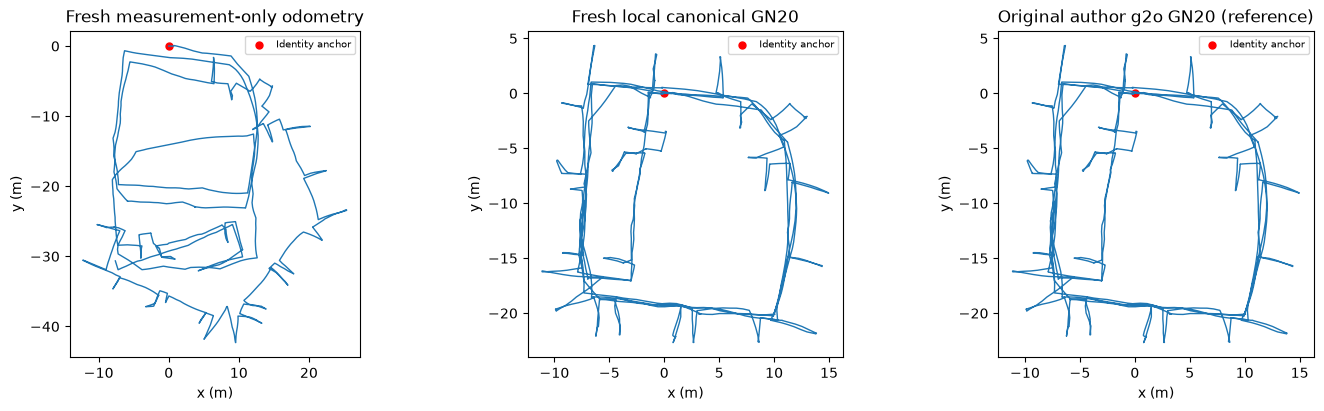

In [3]:
trajectory_figure(initial,fresh,ref,data)
plt.show()

## Full physical observation consistency
Every edge is displayed, including the more inconsistent loop constraints. Translation and heading residuals have separate physical units. A low weighted error alone does not prove absolute map accuracy, and the nominal information need not correspond to independent Gaussian noise.

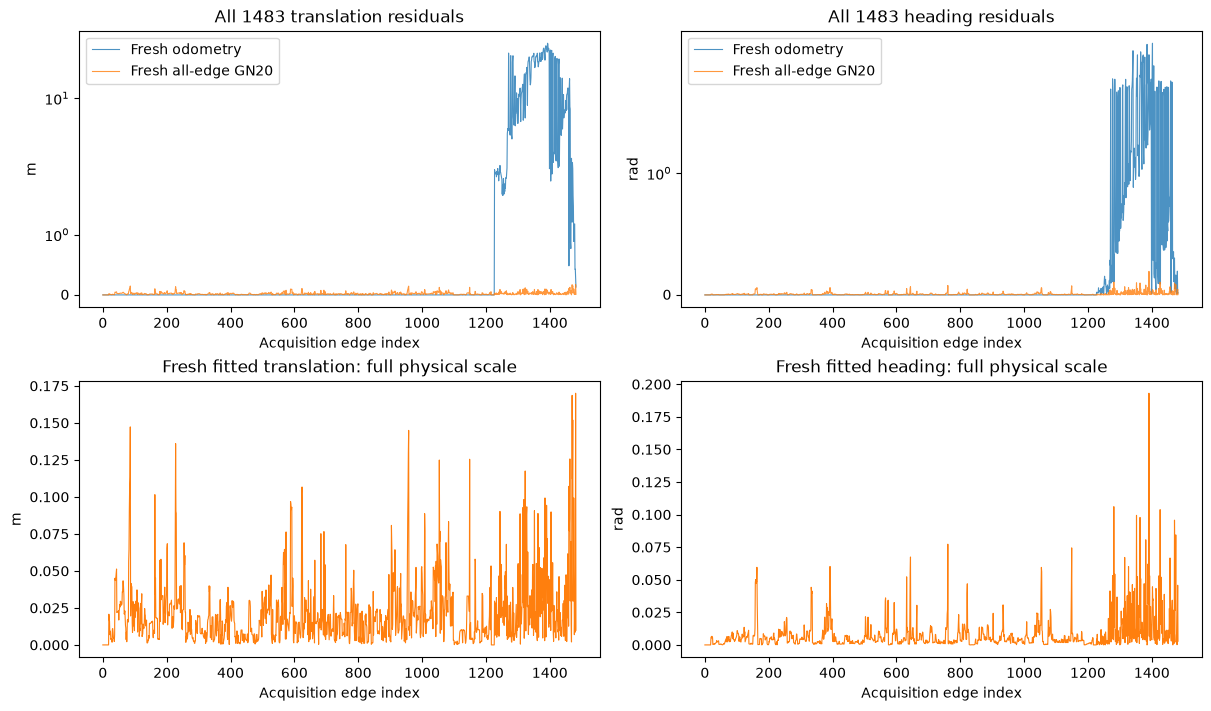

Condition | translation vector RMS (m) | heading RMS (rad) | full weighted sum
fresh odometry 6.394879932386141 0.45480169280706434 5149701.975168909
fresh all-edge GN20 0.03020473595507015 0.015082916718641436 215.83023494628148
original g2o GN20 0.030204735955068326 0.015082916718641502 215.83023494600013


In [4]:
residual_figure(initial,fresh,data)
plt.show()
print('Condition | translation vector RMS (m) | heading RMS (rad) | full weighted sum')
for name,x in [('fresh odometry',initial),('fresh all-edge GN20',fresh),('original g2o GN20',ref)]:
    e=residual_jacobians(x,data)[0]
    print(name,float(np.sqrt(np.mean(np.sum(e[:,:2]**2,axis=1)))),float(np.sqrt(np.mean(e[:,2]**2))),weighted_error(x,data))

## Convergence and method agreement
The source's undamped Gauss-Newton schedule initially increases the objective. Its later convergence is reproduced rather than hidden by a changed line search. Position and circular-heading comparison plots remain in separate units and use the full fixed-gauge trajectory. Tiny discrepancies measure numerical implementation agreement only.

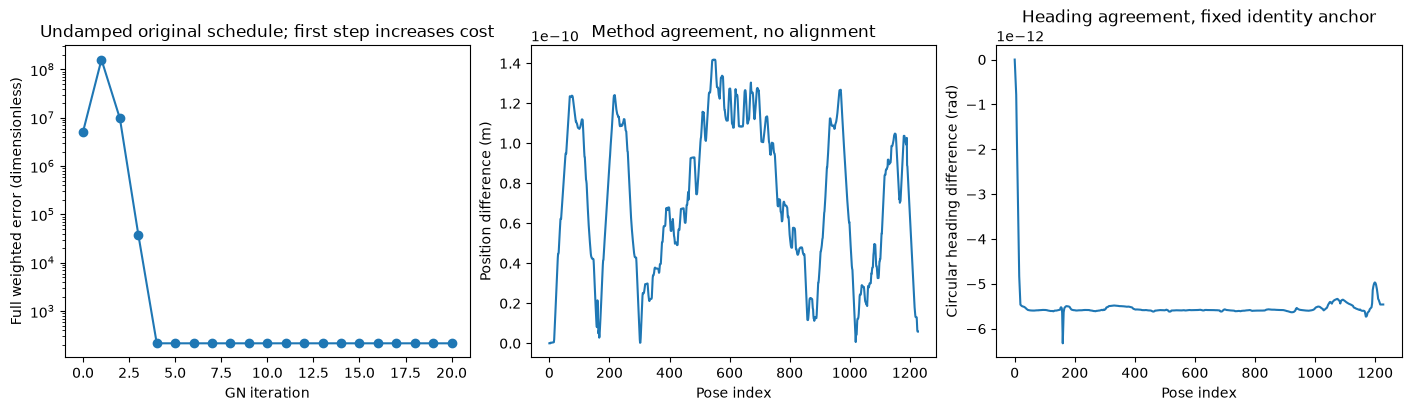

{
  "status": "pass",
  "passed": true,
  "metrics": {
    "position_max_error_m": 1.4185303636300152e-10,
    "heading_max_error_rad": 6.325606705104292e-12,
    "weighted_observation_error": 215.83023494628148
  },
  "thresholds": {
    "position_max_error_m": {
      "comparison": "<=",
      "boundary": 0.0001
    },
    "heading_max_error_rad": {
      "comparison": "<=",
      "boundary": 1e-05
    },
    "weighted_observation_error": {
      "comparison": "<=",
      "boundary": 237.41325844070434
    }
  },
  "errors": []
}


In [5]:
convergence_figure(history,fresh,ref)
plt.show()
import subprocess
result=subprocess.run([sys.executable,str(T/'evaluation/judge.py'),'--prediction',str(T/'output/reconstruction.npz'),'--report',str(T/'output/judge_report.json')],cwd=T,capture_output=True,text=True)
print((T/'output/judge_report.json').read_text())
assert result.returncode==0,result.stderr

## Conclusion and limitations
The fresh local reconstruction uses all real observations and agrees with independently executed original g2o at the original frozen final tolerances. Observation-only odometry and all-edge reconstruction expose the effect of global consistency. The final error is about 215.83, with physical residual RMS about .0302 m and .0151 rad. The complete all-edge independent matrix-group finite-difference and frozen numerical tests validate the chosen chart and derivatives.

The exact dataset has 1228 poses/1483 edges, differing from the graph used in the 2011 paper's experiment. Raw wheel counts/scans, precise time stamps and independent absolute trajectory truth are unavailable. Strong nominal weights make the initial linear system nearly numerically singular; first-step coordinates are not a portable invariant. No claim of calibrated statistical uncertainty or independent physical truth follows from reference agreement.

References: Kummerle et al., ICRA 2011, DOI 10.1109/ICRA.2011.5979949; Carlone and Censi, IEEE TRO 2014, DOI 10.1109/TRO.2013.2291626. Data acquisition attribution: Intel Seattle, Dirk Hahnel; processed dataset attribution: Luca Carlone. All source/permission and native run evidence is indexed in `test/validation.md`.